# Pneumonia Detection from Dataset Exploration

This Notebook explores the chest X-ray dataset used to detect pneumonia

Dataset structure
- train/
- val/
- test/

Classes or Labels
- `NORMAL`
- `PNEUMONIA`

GOALS:
- Understand dataset structure
- Count images
- Check images size
- Check class balance
- Visualize dataset and some images

In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

## Dataset Dir and Labels

In [ ]:
train_dir = "./dataset_pneumonia/train"
val_dir = "./dataset_pneumonia/val"
test_dir = "./dataset_pneumonia/test"

print("Train Labels:", os.listdir(train_dir))
print("Validation Labels:", os.listdir(val_dir))
print("Test classes:", os.listdir(test_dir))


Train Labels: ['NORMAL', 'PNEUMONIA']
Validation Labels: ['NORMAL', 'PNEUMONIA']
Test classes: ['NORMAL', 'PNEUMONIA']


### Nbr of images per classes for each dir

In [27]:
def count_images(dir):
    total = 0
    for label in os.listdir(dir):
        path = os.path.join(dir, label)
        total += len(os.listdir(path))
    return total

print("Train images:", count_images(train_dir))
print("Validation images:", count_images(val_dir))
print("Test images:", count_images(test_dir))

Train images: 6800
Validation images: 1700
Test images: 624


### Sizes of images of each dir

In [28]:
def get_image_sizes(folder):
    sizes = []

    for label in os.listdir(folder):
        path = os.path.join(folder, label)

        for file in os.listdir(path):
            img_path = os.path.join(path, file)

            with Image.open(img_path) as img:
                sizes.append(img.size)

    return sizes

print("Sizes of train_dir", get_image_sizes(train_dir))
print("Sizes of test_dir", get_image_sizes(test_dir))
print("Sizes of val_dir", get_image_sizes(val_dir))

Sizes of train_dir [(1778, 1337), (1906, 1527), (1546, 1307), (1616, 1147), (2170, 1953), (1870, 1638), (1620, 1159), (2144, 1805), (1222, 970), (2218, 2183), (1970, 1554), (1858, 1692), (1592, 1148), (1952, 1496), (2746, 2382), (2090, 1785), (1550, 1452), (2034, 1392), (1724, 1638), (1462, 1140), (1198, 931), (1920, 1708), (2179, 1604), (1756, 1484), (2517, 1979), (1546, 1152), (1611, 1454), (2844, 2067), (1472, 1225), (1620, 1110), (1828, 1437), (1284, 1078), (1634, 1341), (1678, 1229), (1662, 1241), (1902, 1495), (1696, 1330), (1570, 1499), (1904, 1534), (1388, 1094), (1716, 1569), (1762, 1430), (1450, 1210), (1426, 1101), (1788, 1282), (1504, 1174), (1962, 2169), (2006, 1878), (1816, 1607), (1554, 1198), (1600, 1380), (1994, 1839), (1508, 1093), (1476, 1013), (1400, 1125), (1704, 1553), (1124, 716), (1857, 1815), (1856, 1333), (1724, 1480), (2252, 1913), (1770, 1387), (1736, 1345), (1246, 931), (1654, 1446), (1392, 912), (2916, 2583), (1588, 1144), (1466, 1178), (1410, 1106), (1342

### Conclusion for images size

The sizes of img show that all img don't have the same sizes which may affect the model performance, so it has to be resize for better training

## Balance of each dir

In [29]:
def count_per_classes(dir):
    counts = {}
    for label in os.listdir(dir):
        path = os.path.join(dir, label)
        counts[label] = len(os.listdir(path))
    return counts
print("Train balance:", count_per_classes(train_dir))
print("Validation balance:", count_per_classes(val_dir))
print("Test balance:", count_per_classes(test_dir))


Train balance: {'NORMAL': 3400, 'PNEUMONIA': 3400}
Validation balance: {'NORMAL': 850, 'PNEUMONIA': 850}
Test balance: {'NORMAL': 234, 'PNEUMONIA': 390}


### Class Distribution Analysis

The test dir shows `234` img normal and `390` pneumonia, thus the dataset is imbalanced.
This can affect model performance and bias predictions toward the majority class.

### Visualization of the dataset to show the imbalanced

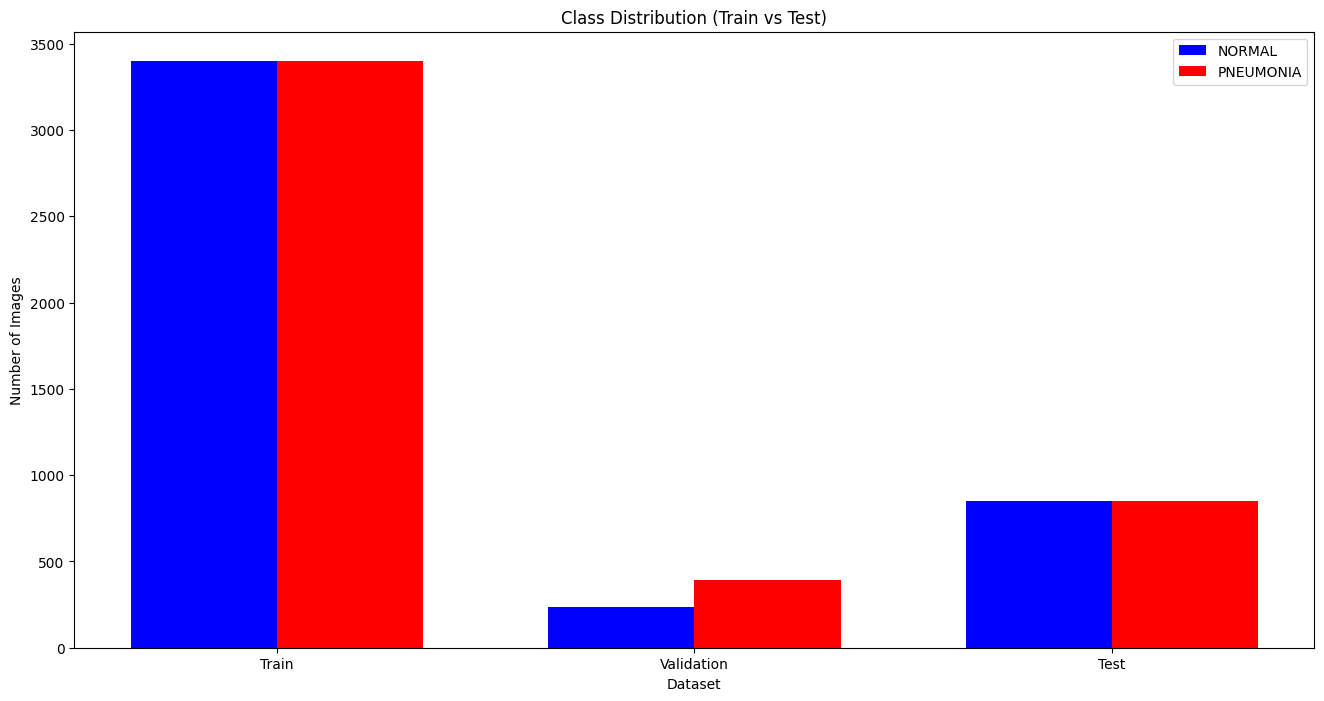

In [30]:
def plot_train_test_balance():
    train_counts = count_per_classes(train_dir)
    test_counts = count_per_classes(test_dir)
    val_counts = count_per_classes(val_dir)
    labels = ["Train", "Validation", "Test"]
    normal_counts = [
        train_counts["NORMAL"],
        test_counts["NORMAL"],
        val_counts["NORMAL"]
    ]
    pneumonia_counts = [
        train_counts["PNEUMONIA"],
        test_counts["PNEUMONIA"],
        val_counts["PNEUMONIA"]
    ]

    x = np.arange(len(labels))
    width = 0.35
    plt.figure(figsize=(16,8))

    plt.bar(x - width/2, normal_counts, width, label="NORMAL", color="blue")
    plt.bar(x + width/2, pneumonia_counts, width, label="PNEUMONIA", color="red")

    plt.xlabel("Dataset")
    plt.ylabel("Number of Images")
    plt.title("Class Distribution (Train vs Test)")
    plt.xticks(x, labels)
    plt.legend()
    plt.show()
    plt.close()
plot_train_test_balance()

## Displaying some img of dataset

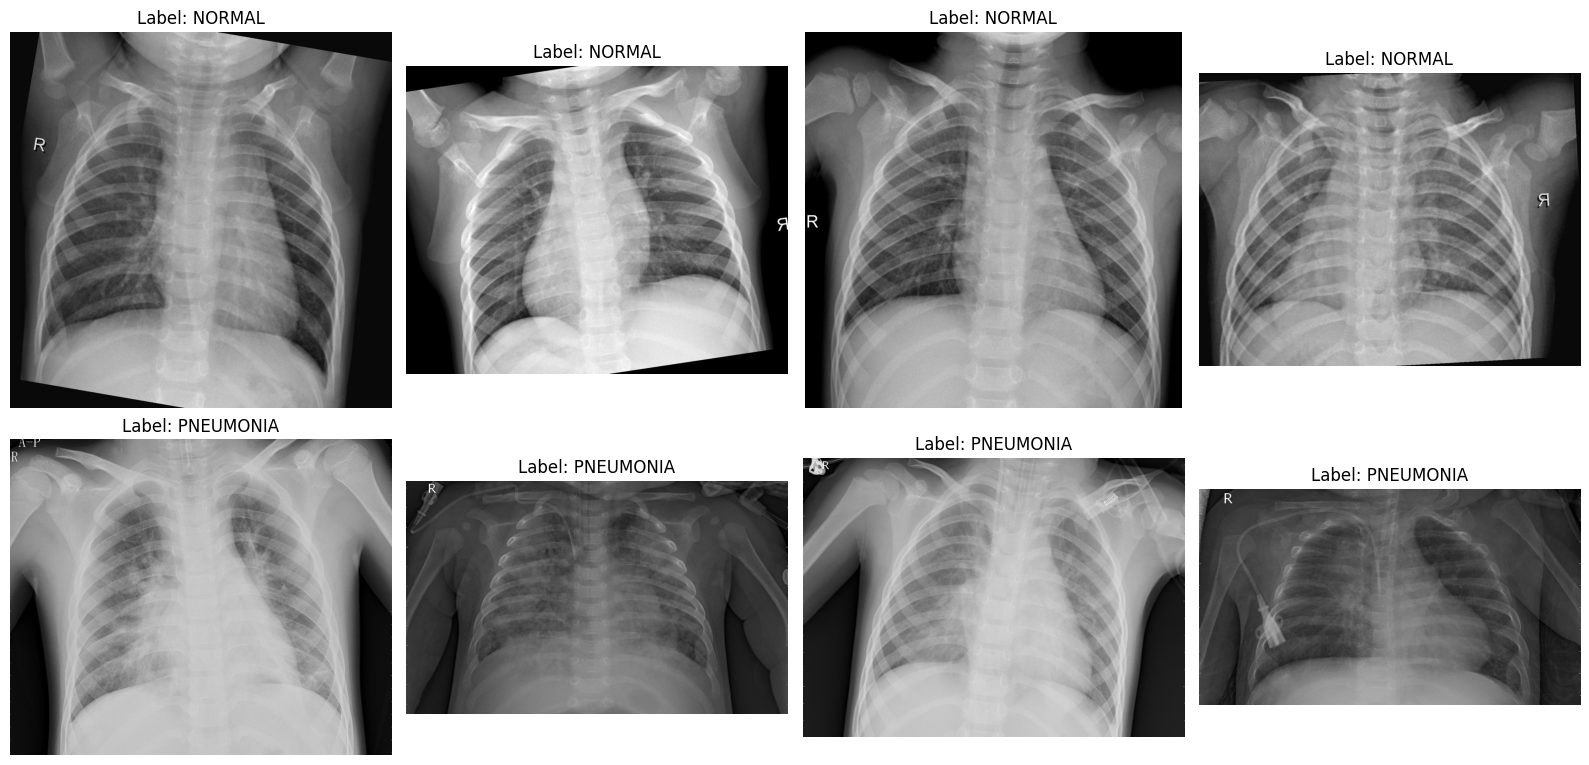

In [31]:


def display_random_img(base_dir, labels=['NORMAL', 'PNEUMONIA'], n=4):
    plt.figure(figsize=(16, 8))
    for i, category in enumerate(labels):
        folder_path = os.path.join(base_dir, category)
        img_names = random.sample(os.listdir(folder_path), n)
        for j, img_name in enumerate(img_names):
            plt.subplot(len(labels), n, i * n + j + 1)
            img_path = os.path.join(folder_path, img_name)
            img = Image.open(img_path)
            plt.imshow(img, cmap='gray')
            plt.title(f"Label: {category}")
            plt.axis('off')
    plt.tight_layout()
    plt.show()

display_random_img(train_dir)